In [ ]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root = Path.cwd()
data_dir = root / "data/processed_classification"
splits = ["train", "val", "test"]
classes = ["D00", "D10", "D20", "D40"]

paths = [p for split in splits for p in sorted((data_dir / split).glob("*/*.jpg"))]
df = pd.DataFrame({"path": paths})
df["split"] = df.path.map(lambda p: p.parent.parent.name)
df["class"] = df.path.map(lambda p: p.parent.name)
df["country"] = df.path.map(lambda p: p.name.split("_")[0])
df["source"] = df.path.map(lambda p: p.stem.split("_obj")[0])
print(f"Tổng số crop: {len(df):,}")
print(f"Số ảnh gốc theo tên file: {df.source.nunique():,}")
print("Các lớp:", ", ".join(sorted(df['class'].unique())))

Tổng số crop: 12,467
Số ảnh gốc theo tên file: 7,726
Các lớp: D00, D10, D20, D40


Notebook khảo sát crop đã gộp của Japan và Czech tại `data/processed_classification`, trước augmentation. Một ảnh gốc có thể tạo nhiều crop.

Chạy crop và `prepare_classification.py` trước, sau đó mở notebook tại thư mục gốc dự án và chạy từ trên xuống. Các số liệu được tính từ dữ liệu hiện có, không dùng lại kết quả của lần chia trước. Notebook chỉ đọc dữ liệu.

In [2]:
for split in splits:
    part = df[df.split == split]
    print(f"{split}: {len(part):,} ảnh ({len(part) / len(df):.2%})")
    print("  " + ", ".join(f"{cls}: {(part['class'] == cls).sum()}" for cls in classes))

print("\nSố ảnh theo quốc gia:")
for country, count in df.country.value_counts().items():
    print(f"{country}: {count:,} ({count / len(df):.2%})")

train: 8,659 ảnh (69.46%)
  D00: 2820, D10: 1889, D20: 2487, D40: 1463
val: 1,925 ảnh (15.44%)
  D00: 599, D10: 405, D20: 543, D40: 378
test: 1,883 ảnh (15.10%)
  D00: 609, D10: 419, D20: 546, D40: 309

Số ảnh theo quốc gia:
Japan: 11,036 (88.52%)
Czech: 1,431 (11.48%)


Train / val / test được chia theo nhóm ảnh gốc với tỷ lệ mục tiêu 70/15/15 ở từng quốc gia, nên tỷ lệ crop có thể lệch nhẹ. Xem kết quả bên trên để kiểm tra số lượng theo tập, lớp và quốc gia.

Khi đánh giá mô hình đã chốt, cần xem recall và F1 từng lớp bên cạnh accuracy tổng. Chênh lệch số lượng giữa các quốc gia có thể ảnh hưởng kết quả chung; không dùng test để chọn mô hình hoặc tinh chỉnh tham số.

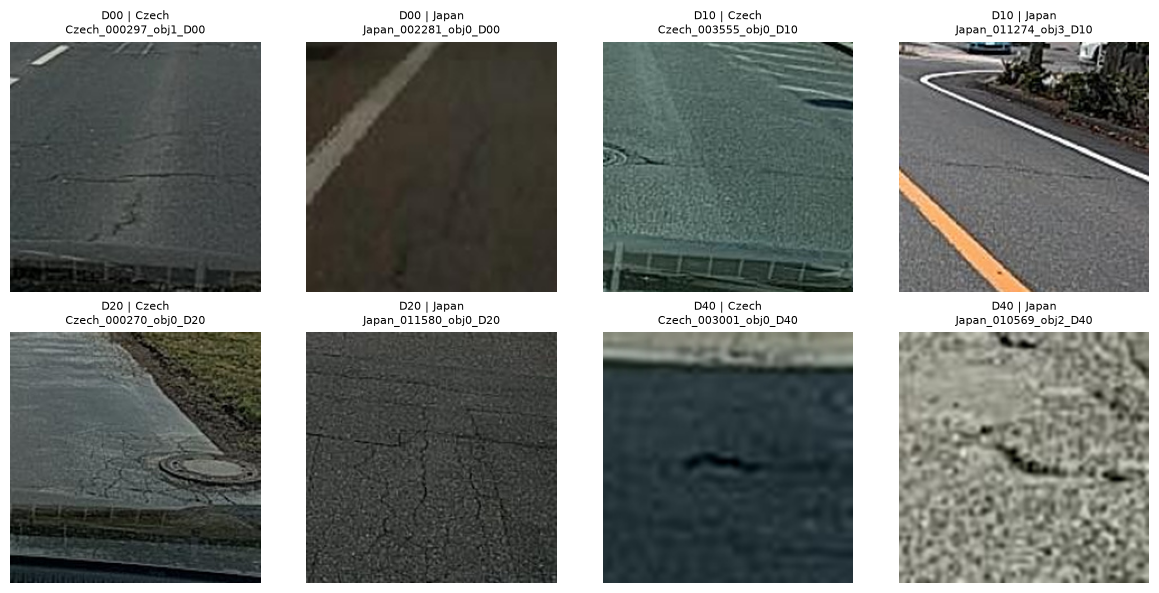

In [3]:
def show_images(data, cols=4, row_names=None):
    rows = (len(data) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, (_, row) in enumerate(data.iterrows()):
        ax = axes.flat[i]
        with Image.open(row.path) as img:
            ax.imshow(img.convert("RGB"))
        title = f"{row['class']} | {row.country}\n{row.path.stem}"
        if row_names is not None:
            title = row_names[i // cols] + "\n" + title
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.show()

train = df[df.split == "train"]
sample = train.groupby(["class", "country"]).sample(n=1, random_state=42)
show_images(sample.sort_values(["class", "country"]))

Lưới lấy 1 ảnh train cho mỗi lớp ở mỗi quốc gia, tổng cộng 8 ảnh, để cả Japan và Czech đều có mặt. Xem mẫu giúp quan sát vùng tổn thương và phần ngữ cảnh còn lại sau crop.

In [4]:
info = []
for row in df.itertuples():
    with Image.open(row.path) as img:
        arr = np.asarray(img.convert("RGB"))
    gray = arr.mean(axis=2) / 255
    key = hashlib.sha256(str(arr.shape).encode() + arr.tobytes()).hexdigest()
    info.append([gray.mean(), gray.std(), key])

stats = pd.DataFrame(info, columns=["brightness", "contrast", "hash"], index=df.index)
images = df.join(stats)

source_splits = df.groupby("source").split.nunique()
groups = images.groupby("hash")
print("Ảnh gốc xuất hiện ở nhiều tập:", (source_splits > 1).sum())
print("Nhóm ảnh trùng pixel:", (groups.size() > 1).sum())
print("Nhóm trùng pixel giữa các tập:", (groups.split.nunique() > 1).sum())
print("Nhóm trùng pixel nhưng khác nhãn:", (groups['class'].nunique() > 1).sum())

Ảnh gốc xuất hiện ở nhiều tập: 0
Nhóm ảnh trùng pixel: 0
Nhóm trùng pixel giữa các tập: 0
Nhóm trùng pixel nhưng khác nhãn: 0


Cell bên trên kiểm tra ảnh gốc xuất hiện ở nhiều tập và nhóm crop trùng pixel, kể cả trùng pixel nhưng khác nhãn. Kiểm tra các bộ đếm sau mỗi lần chạy; các bộ đếm rò rỉ giữa tập phải bằng 0 trước khi huấn luyện. Kiểm tra này không phát hiện mọi ảnh gần trùng hoặc các khung hình cùng tuyến đường.

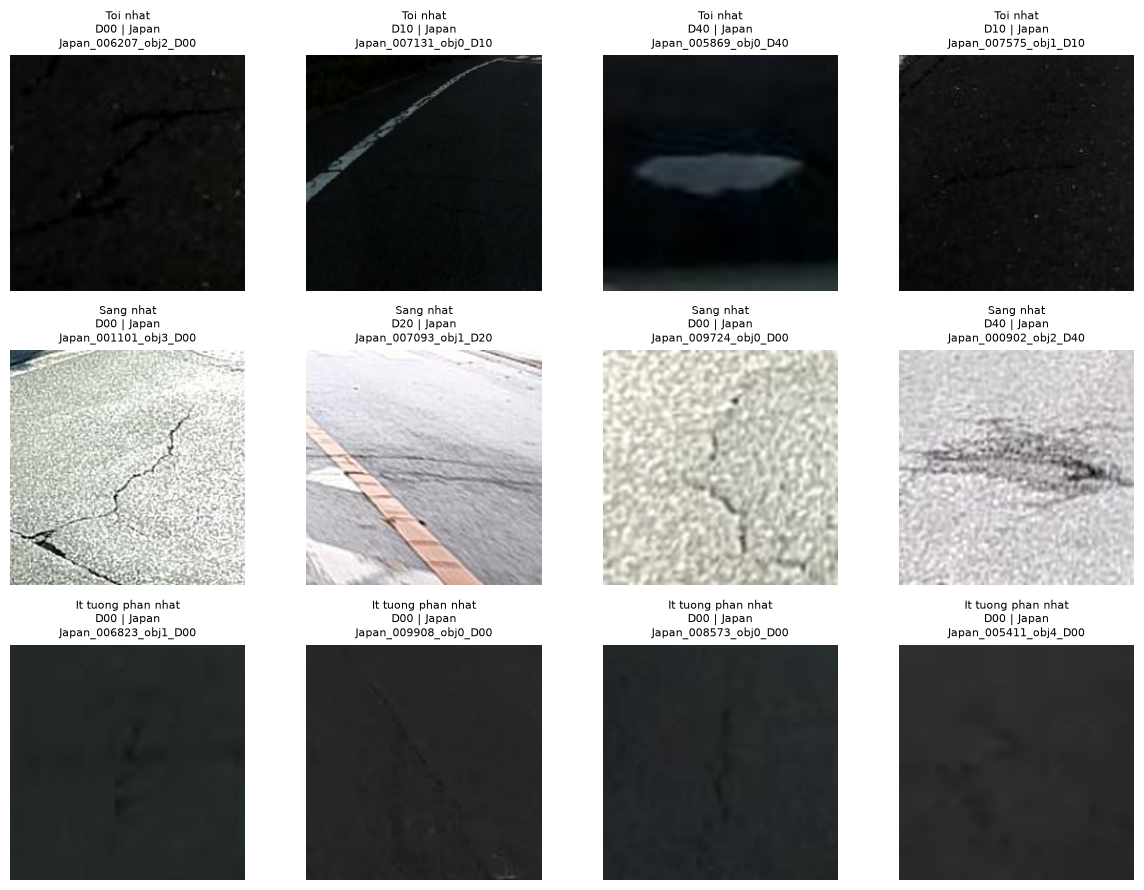

In [5]:
train_img = images[images.split == "train"]
examples = pd.concat([
    train_img.nsmallest(4, "brightness"),
    train_img.nlargest(4, "brightness"),
    train_img.nsmallest(4, "contrast"),
])
show_images(examples, row_names=["Toi nhat", "Sang nhat", "It tuong phan nhat"])

Ba hàng lần lượt là 4 ảnh tối nhất, 4 ảnh sáng nhất và 4 ảnh ít tương phản nhất của train. Một ảnh có thể nằm trong nhiều nhóm.